In [ ]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
import scienceplots


# Costum plots
plt.style.use(['science'])
plt.rcParams["figure.figsize"] = (14/2.54, 8.4/2.54)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["xtick.labelsize"] = 9
plt.rcParams["ytick.labelsize"] = 9
plt.rcParams["legend.fontsize"] = 9

**Generate random variables**

In [2]:
# Seed for random number generator
rng = np.random.default_rng(seed=999)

# Mean, number of random variables and number of experiments
mean = 0.35             
n = 20
num_exp = 1_000_000

# Generate data (1.000.000 rows and 20 columns)
data_raw = rng.binomial(n=1, p=mean, size=(num_exp,n))

**Plot: mpirical frequency of observing $\frac{1}{20} \sum^{20}_{i=1} X_i \geq \alpha$ for $\alpha \in \{0.5,0.55,0.6,...,0.95,1\}$**

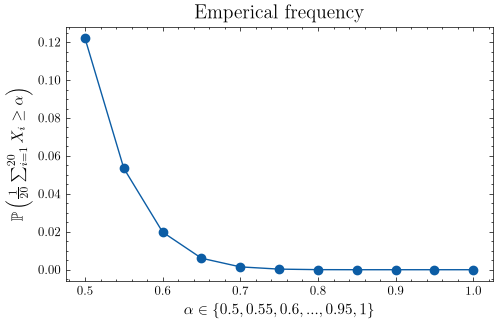

In [3]:
# Define alpha
alpha = np.linspace(0.5, 1, 11)

# Calculate mean of rows
data_mean = np.mean(data_raw, axis = 1)

# Calulate frquency
emp_freq = (data_mean[:, None] >= alpha[None, :]).mean(axis=0)

# Create plot
plt.plot(alpha, emp_freq, marker='o')
plt.xlabel(r"$\alpha \in \{0.5,0.55,0.6,...,0.95,1\}$")
plt.ylabel(r"$\mathbb{P}\left(\frac{1}{20}\sum^{20}_{i=1} X_i \geq \alpha\right)$")
plt.title(r"Emperical frequency")
    
output_dir = "output/"
filename = "emp_frq.png"
plt.savefig(output_dir + filename, dpi=300, bbox_inches="tight")
# plt.close()


**Plot: Markov’s bound $\mathbb{P}\left(\frac{1}{20}\sum_{i=1}^{20} X_i \geq \alpha\right) \leq \frac{\mathbb{E}[\bar{X}]}{\alpha} = \frac{0.35}{\alpha}$**

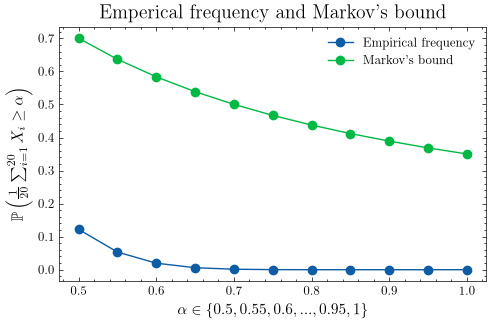

In [4]:
# Calculate Markov's bound (empirical)
mark_bound = (data_mean[:, None] / alpha[None, :]).mean(axis=0)

# Calculate Markov's bound (theoretical)
# mark_bound = mean / alpha

# Create plot
plt.plot(alpha, emp_freq, marker='o', label=r"Empirical frequency")
plt.plot(alpha, mark_bound, marker='o', label=r"Markov's bound")
plt.xlabel(r"$\alpha \in \{0.5,0.55,0.6,...,0.95,1\}$")
plt.ylabel(r"$\mathbb{P}\left(\frac{1}{20}\sum^{20}_{i=1} X_i \geq \alpha\right)$")
plt.title(r"Emperical frequency and Markov's bound")
plt.legend()
    
output_dir = "output/"
filename = "mark_bound.png"
plt.savefig(output_dir + filename, dpi=300, bbox_inches="tight")
# plt.close()

**Plot: Chebyshev’s bound $\mathbb{P}\left(\frac{1}{20}\sum_{i=1}^{20}X_i \ge \alpha\right)
\le \mathbb{P}\left(\left|\frac{1}{20}\sum_{i=1}^{20}X_i - \mu\right| \ge \alpha - \mu\right)
\le \frac{\mathrm{Var}(X_1)}{20(\alpha-\mu)^2}$**

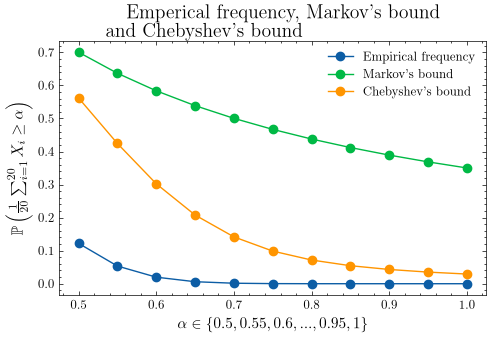

In [5]:
# Calculate Chebyshev's bound (empirical)
data_var = np.var(data_raw, axis=1) # Calculate variance
heby_bound = data_var[:, None] / (20 * ((alpha[None, :] - data_mean[:, None])**2)+1e-6) # Calculate bound
heby_bound = np.where(heby_bound > 1, 1, heby_bound).mean(axis=0) # Set maximum bound to 1 and take mean

# Calculate Chebyshev's bound (theoretical)
# var = np.var(data_raw) # Calculate variance
# heby_bound = var / (20 * (alpha - mean)**2) # Calculate bound

# Create plot
plt.plot(alpha, emp_freq, marker='o', label=r"Empirical frequency")
plt.plot(alpha, mark_bound, marker='o', label=r"Markov's bound")
plt.plot(alpha, heby_bound, marker='o', label=r"Chebyshev's bound")
plt.xlabel(r"$\alpha \in \{0.5,0.55,0.6,...,0.95,1\}$")
plt.ylabel(r"$\mathbb{P}\left(\frac{1}{20}\sum^{20}_{i=1} X_i \geq \alpha\right)$")
plt.title(r"Emperical frequency, Markov's bound \\ and Chebyshev's bound")
plt.legend()
    
output_dir = "output/"
filename = "heby_bound.png"
plt.savefig(output_dir + filename, dpi=300, bbox_inches="tight")
# plt.close()


**Plot: Hoeffding’s bound $\mathbb{P}\left(\frac{1}{20}\sum_{i=1}^{20}X_i \ge \alpha\right)
= \mathbb{P}\big(S_{20}-\mathbb{E}[S_{20}]\ge \varepsilon\big)
\le e^{\frac{-2\varepsilon^2}{20}}
$**

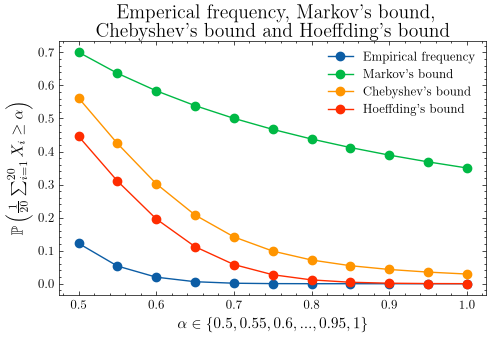

In [6]:
# Calculate Hoeffding's bound (empirical)
epsilon = 20 * (alpha[None, :] - data_mean[:, None])
hoef_bound = np.exp((-2 * epsilon**2)/n).mean(axis=0)


# Calculate Hoeffding's bound (theoretical)
# epsilon = 20 * (alpha - mean)
# hoef_bound = np.exp((-2 * epsilon**2)/n)

# Create plot
plt.plot(alpha, emp_freq, marker='o', label=r"Empirical frequency")
plt.plot(alpha, mark_bound, marker='o', label=r"Markov's bound")
plt.plot(alpha, heby_bound, marker='o', label=r"Chebyshev's bound")
plt.plot(alpha, hoef_bound, marker='o', label=r"Hoeffding's bound")
plt.xlabel(r"$\alpha \in \{0.5,0.55,0.6,...,0.95,1\}$")
plt.ylabel(r"$\mathbb{P}\left(\frac{1}{20}\sum^{20}_{i=1} X_i \geq \alpha\right)$")
plt.title(r"Emperical frequency, Markov's bound, \\ Chebyshev's bound and Hoeffding's bound")
plt.legend()
    
output_dir = "output/"
filename = "hoef_bound.png"
plt.savefig(output_dir + filename, dpi=300, bbox_inches="tight")
# plt.close()


**CLT**

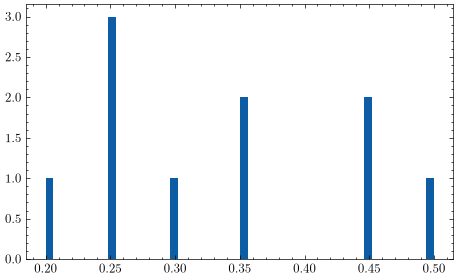

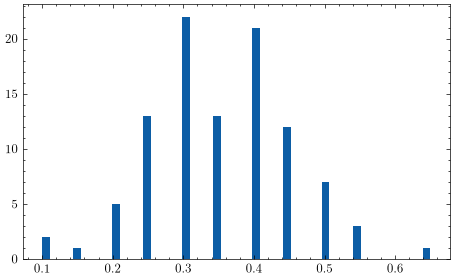

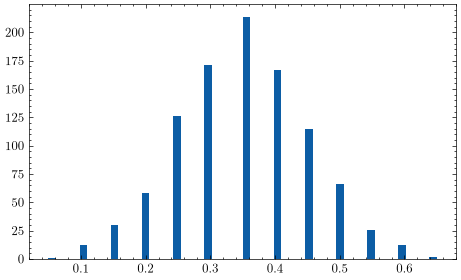

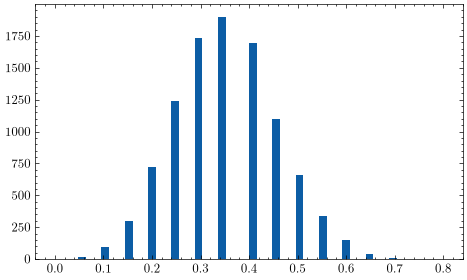

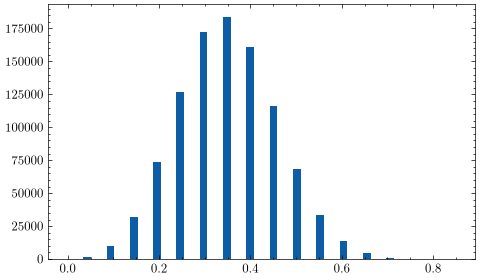

In [7]:
plt.hist(data_mean[:10],bins=50)
plt.show()

plt.hist(data_mean[:100],bins=50)
plt.show()

plt.hist(data_mean[:1000],bins=50)
plt.show()

plt.hist(data_mean[:10000],bins=50)
plt.show()

plt.hist(data_mean[:1000000],bins=50)
plt.show()